## Partie 1 — Données

Objectif de cette partie : comprendre le jeu de données, mesurer sa répartition, puis le charger proprement pour l'entraînement Keras. Le code est découpé en petites étapes, chacune avec son rôle.

### 1.1 D'où vient FER-2013 ?

**FER-2013** (*Facial Expression Recognition 2013*) a été constitué par Pierre-Luc Carrier et Aaron Courville (Université de Montréal) pour un défi Kaggle du workshop *Challenges in Representation Learning* de la conférence ICML 2013.

Constitution :

- les images ont été collectées automatiquement avec la recherche d'images Google, à partir de mots-clés liés aux émotions ;
- les visages ont été détectés, recadrés et centrés automatiquement ;
- chaque visage a été converti en **niveaux de gris** et ramené à **48×48 pixels** ;
- chaque image porte une des **7 émotions** : 0 colère, 1 dégoût, 2 peur, 3 joie, 4 tristesse, 5 surprise, 6 neutre.

Le jeu original est un fichier CSV (`fer2013.csv`) : une ligne par image, avec le label, les 2 304 pixels, et une colonne `Usage` qui fixe le découpage : `Training` (28 709 images), `PublicTest` (3 589) et `PrivateTest` (3 589).

La version utilisée ici (Kaggle, `msambare/fer2013`) contient les mêmes images, converties en JPEG et rangées en un dossier par émotion. Notre dossier `test` regroupe `PublicTest` et `PrivateTest` : on le vérifie plus bas grâce aux noms de fichiers.

Limites connues, utiles pour interpréter nos résultats :

- les labels sont bruités (collecte automatique) : les auteurs estiment la précision humaine à environ **65 % ± 5 %** sur ce jeu ;
- le gagnant du défi a obtenu environ 71 % d'accuracy ;
- les classes sont déséquilibrées (on le mesure ci-dessous).

**Référence :** I. Goodfellow et al., *Challenges in Representation Learning: A report on three machine learning contests*, ICONIP 2013 ([arXiv:1307.0414](https://arxiv.org/abs/1307.0414)).

**Licence :** pas de licence open source explicite. Le jeu est diffusé pour la recherche via la compétition Kaggle d'origine ; nous l'utilisons uniquement dans un cadre académique et ne le redistribuons pas (les images ne sont pas dans le dépôt git).

### 1.2 Imports et constantes

On utilise des outils classiques :

- `pathlib` pour lister les fichiers ;
- **OpenCV** (`cv2`) pour lire et transformer les images ;
- **NumPy** pour stocker les images sous forme de tableaux ;
- **pandas** pour les tableaux de comptage ;
- **Matplotlib / seaborn** pour les graphiques ;
- **scikit-learn** pour le découpage train / validation.

`SEED` fixe le hasard pour que le découpage et les exemples affichés soient reproductibles.

In [71]:
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

L'ordre des classes est fixé une fois pour toutes : il reprend la numérotation officielle de FER-2013 (0 à 6). Le même ordre servira pour les labels, la couche Softmax, la matrice de confusion et la vidéo.

In [72]:
CLASS_NAMES = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

IMAGE_SIZE = (48, 48)
SPLITS = ["train", "test"]

CLASS_TO_INDEX

{'angry': 0,
 'disgust': 1,
 'fear': 2,
 'happy': 3,
 'sad': 4,
 'surprise': 5,
 'neutral': 6}

### 1.3 Localiser les données

Les images sont rangées ainsi :

```text
data/train/<emotion>/*.jpg
data/test/<emotion>/*.jpg
```

La cellule cherche le dossier `data/` depuis le notebook (`../data`) ou depuis la racine du projet. Sur Google Colab, renseigner `DATA_DIR` à la main (par exemple un dossier de Google Drive monté).

In [73]:
candidates = [Path("../data"), Path("data"), Path("/content/data")]
DATA_DIR = next((path for path in candidates if (path / "train").is_dir()), None)
assert DATA_DIR is not None, "Dossier data/ introuvable : renseigner DATA_DIR à la main."

for split in SPLITS:
    folders = sorted(path.name for path in (DATA_DIR / split).iterdir() if path.is_dir())
    assert set(folders) == set(CLASS_NAMES), f"{split} : dossiers inattendus {folders}"

DATA_DIR.resolve()

PosixPath('/Users/ftayma24/SKOOL/ING3/DL/ProjetDL/data')

### 1.4 Inventaire des fichiers

On construit un dictionnaire `image_paths[split][emotion]` qui contient la liste des chemins d'images. On ne lit pas encore les images : on sépare l'inventaire (rapide) du chargement (plus long).

In [74]:
image_paths = {
    split: {
        name: sorted((DATA_DIR / split / name).glob("*.jpg"))
        for name in CLASS_NAMES
    }
    for split in SPLITS
}

image_paths["train"]["happy"][:3]

[PosixPath('../data/train/happy/Training_10019449.jpg'),
 PosixPath('../data/train/happy/Training_10046809.jpg'),
 PosixPath('../data/train/happy/Training_10066226.jpg')]

### 1.5 Combien d'images par ensemble et par émotion ?

In [75]:
counts = pd.DataFrame(
    {split: {name: len(paths) for name, paths in image_paths[split].items()} for split in SPLITS}
).loc[CLASS_NAMES]

counts["total"] = counts.sum(axis=1)
counts.loc["total"] = counts.sum()
counts

,train,test,total
angry,3995,958,4953
disgust,436,111,547
fear,4097,1024,5121
happy,7215,1774,8989
sad,4830,1247,6077
surprise,3171,831,4002
neutral,4965,1233,6198
total,28709,7178,35887


Part de chaque ensemble dans le total des images :

In [76]:
n_train = counts.loc["total", "train"]
n_test = counts.loc["total", "test"]
n_total = n_train + n_test

split_share = pd.DataFrame(
    {
        "images": [n_train, n_test, n_total],
        "pourcentage": [100 * n_train / n_total, 100 * n_test / n_total, 100.0],
    },
    index=["train", "test", "total"],
).round(2)

split_share

,images,pourcentage
train,28709,80.0
test,7178,20.0
total,35887,100.0


Le découpage fourni est donc d'environ **80 % train / 20 % test**.

Vérification de l'origine des fichiers : le préfixe du nom de fichier reprend la colonne `Usage` du CSV d'origine.

In [77]:
origin = pd.DataFrame(
    {
        split: Counter(path.name.split("_")[0] for paths in image_paths[split].values() for path in paths)
        for split in SPLITS
    }
).fillna(0).astype(int)

origin

,train,test
Training,28709,0
PrivateTest,0,3589
PublicTest,0,3589


Le dossier `train` correspond à `Training`, et le dossier `test` à `PublicTest` + `PrivateTest`. Nous gardons ce test officiel intact pour l'évaluation finale.

### 1.6 Répartition par émotion (pourcentages)

Pour chaque ensemble, part de chaque émotion :

In [78]:
class_share = (counts.loc[CLASS_NAMES, SPLITS] / counts.loc["total", SPLITS] * 100).round(2)
class_share

,train,test
angry,13.92,13.35
disgust,1.52,1.55
fear,14.27,14.27
happy,25.13,24.71
sad,16.82,17.37
surprise,11.05,11.58
neutral,17.29,17.18


### 1.7 Histogrammes : nombre d'images par émotion

Un graphique par ensemble. Les effectifs sont écrits au-dessus des barres.

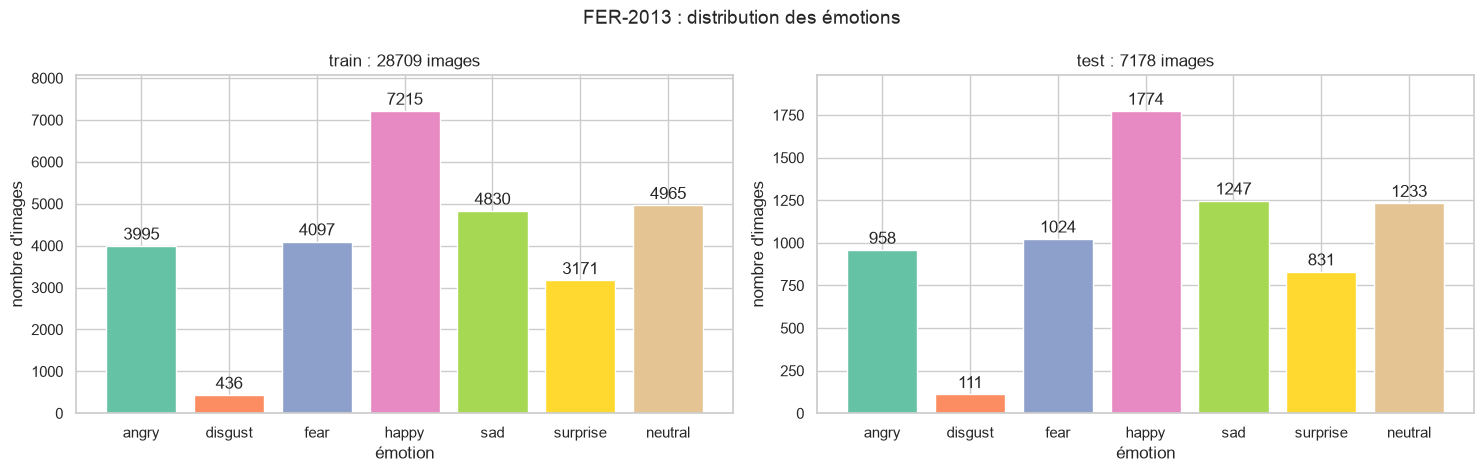

In [79]:
palette = sns.color_palette("Set2", NUM_CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, split in zip(axes, SPLITS):
    values = counts.loc[CLASS_NAMES, split]
    bars = ax.bar(CLASS_NAMES, values, color=palette)
    ax.bar_label(bars, padding=2)
    ax.set_title(f"{split} : {values.sum()} images")
    ax.set_xlabel("émotion")
    ax.set_ylabel("nombre d'images")
    ax.margins(y=0.12)

plt.suptitle("FER-2013 : distribution des émotions", fontsize=14)
plt.tight_layout()
plt.show()

Comparaison des deux distributions en pourcentage. Si les barres train et test sont à la même hauteur, le test est représentatif du train.

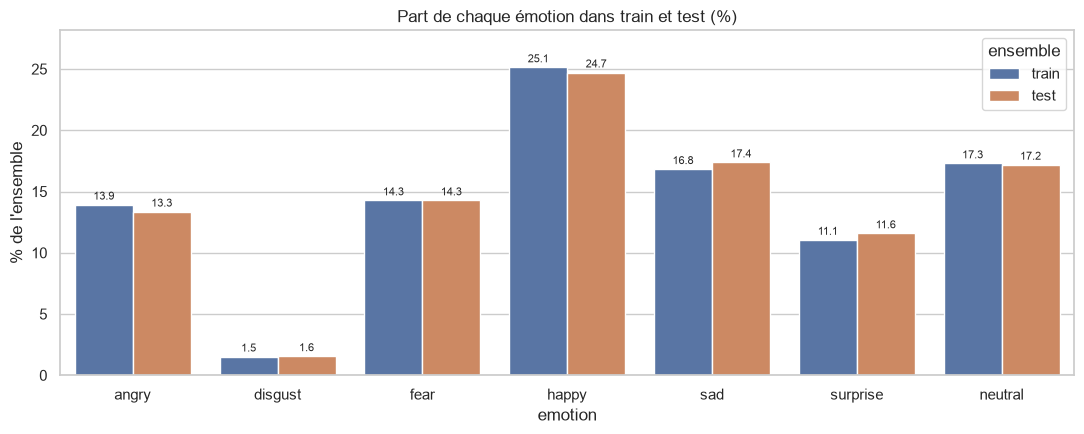

In [80]:
share_long = (
    class_share.reset_index(names="emotion")
    .melt(id_vars="emotion", var_name="ensemble", value_name="pourcentage")
)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=share_long, x="emotion", y="pourcentage", hue="ensemble", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
ax.set_title("Part de chaque émotion dans train et test (%)")
ax.set_ylabel("% de l'ensemble")
ax.margins(y=0.12)
plt.tight_layout()
plt.show()

### 1.8 Déséquilibre des classes

In [81]:
train_counts = counts.loc[CLASS_NAMES, "train"]

print(f"Classe majoritaire : {train_counts.idxmax()} ({train_counts.max()} images)")
print(f"Classe minoritaire : {train_counts.idxmin()} ({train_counts.min()} images)")
print(f"Ratio majoritaire / minoritaire : {train_counts.max() / train_counts.min():.1f}")

Classe majoritaire : happy (7215 images)
Classe minoritaire : disgust (436 images)
Ratio majoritaire / minoritaire : 16.5


Lecture :

- **happy** est la classe la plus représentée (environ un quart des images) ;
- **disgust** est très rare (environ 1,5 % des images) : le modèle la verra peu et aura du mal à la reconnaître ;
- les proportions sont quasiment identiques entre train et test, donc le test reflète bien la distribution d'entraînement.

Conséquences pour la suite : l'accuracy globale ne suffira pas (un modèle peut l'augmenter en ignorant `disgust`). En partie 5, on regardera la précision, le rappel et le F1 par classe, et la matrice de confusion. Des poids de classe sont préparés en 1.14 pour une éventuelle expérience.

### 1.9 Format des images

On lit toutes les images sans conversion (`IMREAD_UNCHANGED`) pour vérifier leur extension, leurs dimensions et leur type de pixels.

In [82]:
all_paths = [path for split in SPLITS for paths in image_paths[split].values() for path in paths]

formats = Counter()
for path in all_paths:
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        formats[(path.suffix.lower(), "illisible", "")] += 1
    else:
        formats[(path.suffix.lower(), image.shape, str(image.dtype))] += 1

pd.DataFrame(
    [(ext, str(shape), dtype, n) for (ext, shape, dtype), n in formats.items()],
    columns=["extension", "shape", "dtype", "images"],
)

,extension,shape,dtype,images
0,.jpg,"(48, 48)",uint8,35887


Toutes les images sont des JPEG **48×48 à un seul canal** (niveaux de gris), pixels entiers `uint8` entre 0 et 255.

### 1.10 Exemples par émotion

Six images tirées au hasard dans le train pour chaque émotion. On voit déjà des cas difficiles : visages de profil, mains devant le visage, filigranes, expressions peu marquées.

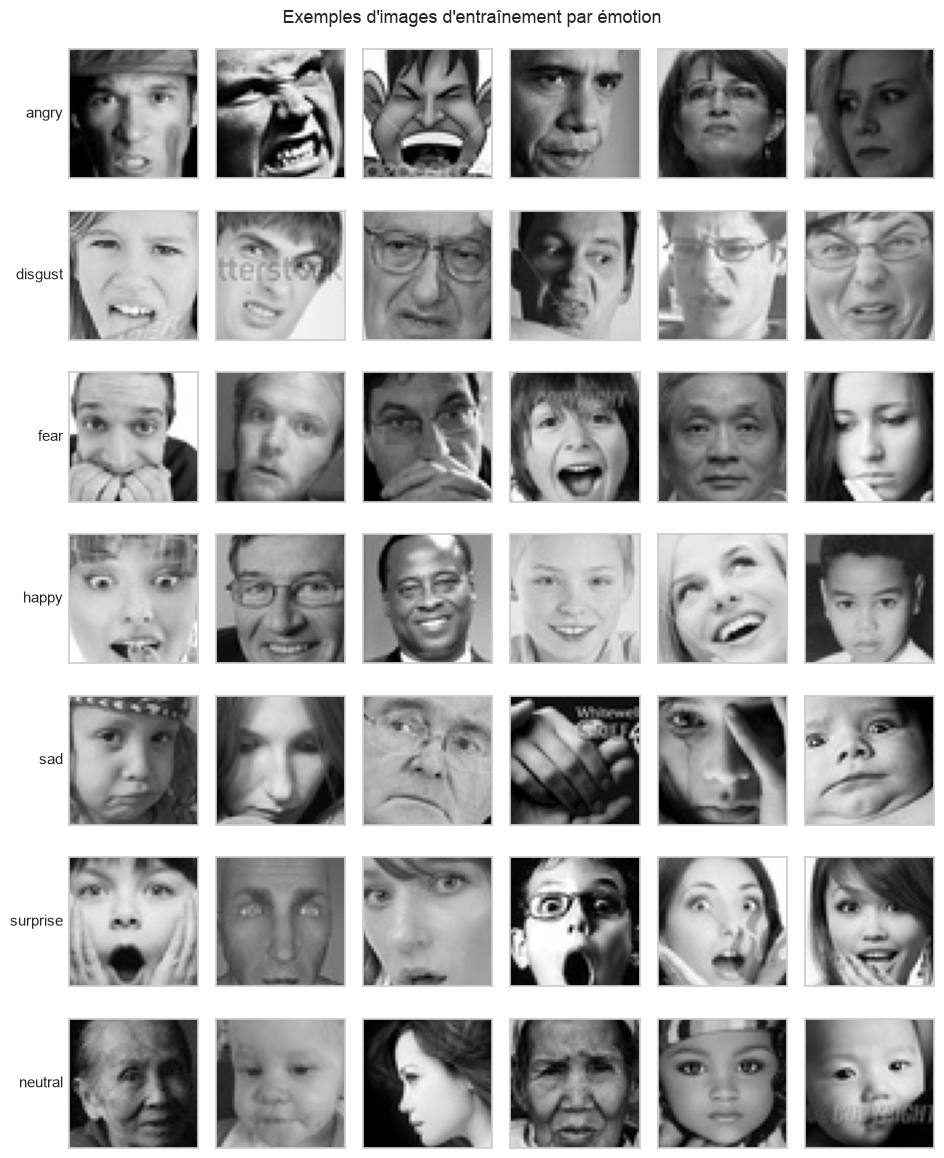

In [83]:
rng = np.random.default_rng(SEED)
n_examples = 6

fig, axes = plt.subplots(NUM_CLASSES, n_examples, figsize=(n_examples * 1.6, NUM_CLASSES * 1.7))
for row, name in enumerate(CLASS_NAMES):
    picks = rng.choice(len(image_paths["train"][name]), size=n_examples, replace=False)
    for col, index in enumerate(picks):
        ax = axes[row, col]
        image = cv2.imread(str(image_paths["train"][name][index]), cv2.IMREAD_GRAYSCALE)
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=11)

plt.suptitle("Exemples d'images d'entraînement par émotion", fontsize=13)
plt.tight_layout()
plt.show()

### 1.11 Prétraitement : `preprocess_face`

Chaque image passe par la même fonction, à l'entraînement comme plus tard sur les visages détectés dans une photo ou une vidéo. C'est ce qui garantit que le modèle voit toujours des entrées comparables.

| Étape | Rôle |
| --- | --- |
| Niveaux de gris | Une seule information de luminosité par pixel, comme dans FER-2013. Un visage en couleur venant d'une caméra est converti. |
| Redimensionnement 48×48 | Un réseau attend une taille d'entrée fixe. FER-2013 est déjà en 48×48, mais un visage détecté plus tard ne le sera pas. |
| Normalisation `/ 255` | Les pixels passent de [0, 255] à [0, 1]. Des entrées petites et de même échelle stabilisent la descente de gradient. |
| Ajout d'un canal | Keras attend une image sous la forme (hauteur, largeur, canaux) : ici (48, 48, 1). |

Pourquoi OpenCV + NumPy plutôt que `keras.utils.image_dataset_from_directory` ? Le jeu tient en mémoire (quelques centaines de Mo), on peut tout inspecter facilement, et la même fonction OpenCV servira aux visages extraits d'une vidéo.

In [84]:
def preprocess_face(image):
    """Image de visage (gris ou BGR, taille quelconque) -> tableau (48, 48, 1) float32 dans [0, 1]."""
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    if image.shape[:2] != IMAGE_SIZE:
        image = cv2.resize(image, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
    image = image.astype("float32") / 255.0
    return image[..., np.newaxis]

Effet de la fonction sur une image :

In [85]:
raw = cv2.imread(str(image_paths["train"]["happy"][0]), cv2.IMREAD_GRAYSCALE)
processed = preprocess_face(raw)

print(f"avant : shape {raw.shape}, dtype {raw.dtype}, min {raw.min()}, max {raw.max()}")
print(f"après : shape {processed.shape}, dtype {processed.dtype}, min {processed.min():.3f}, max {processed.max():.3f}")

avant : shape (48, 48), dtype uint8, min 0, max 255
après : shape (48, 48, 1), dtype float32, min 0.000, max 1.000


### 1.12 Chargement des images

Pour chaque ensemble, on lit chaque image avec OpenCV, on applique `preprocess_face`, et on associe le label entier de son dossier (`happy` → 3, etc.). On obtient :

- `X` : tableau de forme (nombre d'images, 48, 48, 1) ;
- `y` : tableau d'entiers entre 0 et 6.

Le chargement prend quelques secondes.

In [86]:
def load_split(split):
    images, labels = [], []
    for name in CLASS_NAMES:
        for path in image_paths[split][name]:
            image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
            images.append(preprocess_face(image))
            labels.append(CLASS_TO_INDEX[name])
    return np.stack(images), np.array(labels, dtype="int64")

In [87]:
X_train_full, y_train_full = load_split("train")
X_test, y_test = load_split("test")

In [88]:
for name, X, y in [("train complet", X_train_full, y_train_full), ("test", X_test, y_test)]:
    print(f"{name:14s} X {X.shape} {X.dtype}  pixels [{X.min():.1f}, {X.max():.1f}]  y {y.shape} labels {np.unique(y)}")

print(f"Mémoire occupée par les images : {(X_train_full.nbytes + X_test.nbytes) / 1e6:.0f} Mo")

train complet  X (28709, 48, 48, 1) float32  pixels [0.0, 1.0]  y (28709,) labels [0 1 2 3 4 5 6]
test           X (7178, 48, 48, 1) float32  pixels [0.0, 1.0]  y (7178,) labels [0 1 2 3 4 5 6]
Mémoire occupée par les images : 331 Mo


### 1.13 Découpage train / validation / test

Rôle de chaque ensemble :

- **train** : le modèle apprend ses poids dessus ;
- **validation** : on suit le surapprentissage et on compare les réglages (architecture, learning rate, Dropout, Early Stopping…) ;
- **test** : évaluation finale, **une seule fois**, sur le modèle choisi. Il ne sert jamais à choisir un réglage, sinon le score final serait optimiste.

FER-2013 ne fournit que `train` et `test`. On prélève donc **20 % du train** comme validation. Le découpage est **stratifié** : chaque émotion garde la même proportion dans train et validation, ce qui compte pour une classe rare comme `disgust`. `random_state` rend le découpage reproductible.

In [89]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=SEED,
)

print("train      :", X_train.shape, y_train.shape)
print("validation :", X_val.shape, y_val.shape)
print("test       :", X_test.shape, y_test.shape)

train      : (22967, 48, 48, 1) (22967,)
validation : (5742, 48, 48, 1) (5742,)
test       : (7178, 48, 48, 1) (7178,)


Vérification : taille de chaque ensemble et part de chaque émotion. Les trois colonnes de pourcentages doivent être presque identiques.

In [90]:
final_sets = {"train": y_train, "validation": y_val, "test": y_test}

distribution = pd.DataFrame(
    {name: np.bincount(y, minlength=NUM_CLASSES) for name, y in final_sets.items()},
    index=CLASS_NAMES,
)
distribution_pct = (distribution / distribution.sum() * 100).round(2).add_suffix(" %")

pd.concat([distribution, distribution_pct], axis=1)

,train,validation,test,train %,validation %,test %
angry,3196,799,958,13.92,13.92,13.35
disgust,349,87,111,1.52,1.52,1.55
fear,3277,820,1024,14.27,14.28,14.27
happy,5772,1443,1774,25.13,25.13,24.71
sad,3864,966,1247,16.82,16.82,17.37
surprise,2537,634,831,11.05,11.04,11.58
neutral,3972,993,1233,17.29,17.29,17.18


In [91]:
sizes = pd.Series({name: len(y) for name, y in final_sets.items()})
pd.DataFrame({"images": sizes, "pourcentage du total": (sizes / sizes.sum() * 100).round(2)})

,images,pourcentage du total
train,22967,64.0
validation,5742,16.0
test,7178,20.0


Répartition finale : environ **64 % train, 16 % validation, 20 % test**.

### 1.14 Encodage des labels

Les labels sont des entiers (0 à 6). Deux encodages sont possibles avec Keras :

- **entiers** + perte `sparse_categorical_crossentropy` : c'est notre choix, plus léger ;
- **one-hot** + perte `categorical_crossentropy` : chaque label devient un vecteur de 7 valeurs avec un seul 1.

Les deux donnent exactement la même perte. Exemple d'équivalence :

In [92]:
example_labels = y_train[:5]
one_hot = np.eye(NUM_CLASSES, dtype="float32")[example_labels]

pd.DataFrame(one_hot.astype(int), columns=CLASS_NAMES, index=[CLASS_NAMES[i] for i in example_labels])

,angry,disgust,fear,happy,sad,surprise,neutral
neutral,0,0,0,0,0,0,1
happy,0,0,0,1,0,0,0
neutral,0,0,0,0,0,0,1
fear,0,0,1,0,0,0,0
surprise,0,0,0,0,0,1,0


Poids de classe : pour compenser le déséquilibre, Keras peut donner plus d'importance aux erreurs sur les classes rares (`model.fit(..., class_weight=class_weight)`). On les calcule ici sur le train seulement. Leur usage sera une expérience de la partie 6, comparée au modèle sans poids.

In [93]:
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(weights))

pd.Series(weights, index=CLASS_NAMES, name="poids").round(2)

angry       1.03
disgust     9.40
fear        1.00
happy       0.57
sad         0.85
surprise    1.29
neutral     0.83
Name: poids, dtype: float64

### 1.15 Bilan de la préparation

Contrôle des entrées prêtes pour Keras :

In [94]:
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:] == (*IMAGE_SIZE, 1)
assert X_train.dtype == np.float32 and 0.0 <= X_train.min() and X_train.max() <= 1.0
assert set(np.unique(y_train)) == set(range(NUM_CLASSES))

INPUT_SHAPE = X_train.shape[1:]
print("Entrée du réseau :", INPUT_SHAPE, "| classes :", NUM_CLASSES)

Entrée du réseau : (48, 48, 1) | classes : 7


Les données sont prêtes :

- `X_train`, `y_train` : apprentissage ;
- `X_val`, `y_val` : `validation_data` de `model.fit` ;
- `X_test`, `y_test` : évaluation finale uniquement ;
- `INPUT_SHAPE = (48, 48, 1)` et `NUM_CLASSES = 7` pour construire les modèles ;
- `preprocess_face` : prétraitement à réutiliser pour tout nouveau visage.

## Partie 2 — MLP de référence

Avant le CNN, on entraîne un réseau simple, entièrement connecté (*Multi-Layer Perceptron*) :

```text
Image 48×48 → Flatten (2 304 valeurs) → Dense 256 + ReLU → Dense 7 + Softmax
```

Il sert de **point de comparaison** : l'objectif n'est pas d'avoir un bon score, mais de mesurer ce que le CNN apporte ensuite. On profite aussi de ce modèle simple pour illustrer, sur nos données, chaque notion : vecteur d'entrée, poids et biais, propagation avant, activations, Softmax, perte, rétropropagation et descente de gradient.

### 2.1 Imports

Keras est l'interface haut niveau de TensorFlow. `set_random_seed` fixe le hasard (initialisation des poids, ordre des batchs) pour rendre l'entraînement reproductible.

In [95]:
import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(SEED)

MODELS_DIR = DATA_DIR.parent / "models"
REPORTS_DIR = DATA_DIR.parent / "reports"
MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


### 2.2 De l'image au vecteur d'entrée

Un MLP ne sait traiter qu'un **vecteur** de nombres. L'image 48×48 est donc « aplatie » : on met ses 48 lignes de pixels bout à bout, ce qui donne un vecteur de 48 × 48 = **2 304 valeurs** entre 0 et 1. C'est le rôle de la couche `Flatten`.

Conséquence importante : après l'aplatissement, le réseau ne sait plus quels pixels étaient voisins. Un pixel de l'œil et le pixel juste en dessous deviennent deux entrées sans lien. C'est la principale limite du MLP sur des images, et la raison d'être du CNN (partie 3).

In [96]:
image = X_train[0]
vector = image.reshape(-1)

print("image  :", image.shape)
print("vecteur:", vector.shape)
print("10 premières valeurs (première ligne de pixels) :", vector[:10].round(3))

image  : (48, 48, 1)
vecteur: (2304,)
10 premières valeurs (première ligne de pixels) : [0.082 0.075 0.075 0.11  0.122 0.11  0.106 0.106 0.094 0.078]


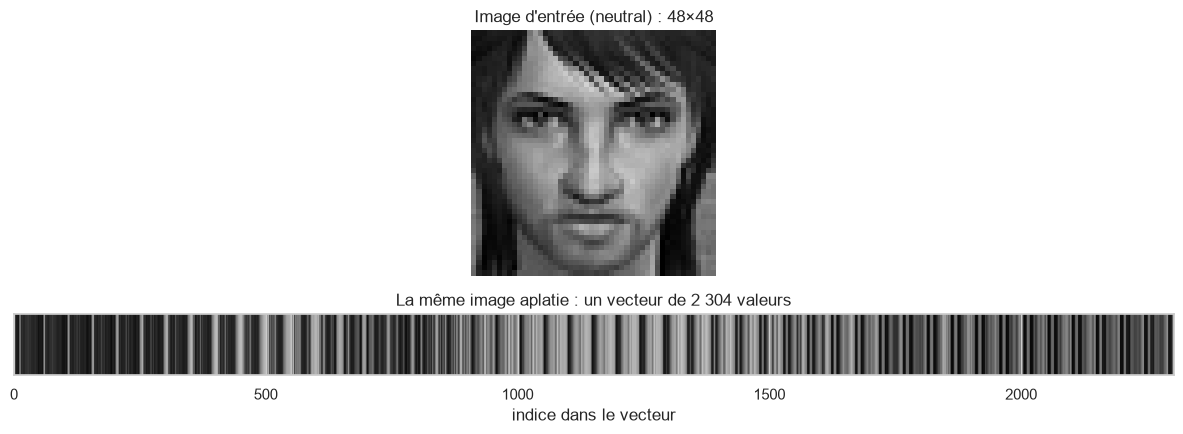

In [97]:
fig, axes = plt.subplots(2, 1, figsize=(12, 4.5), gridspec_kw={"height_ratios": [4, 1]})

axes[0].imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Image d'entrée ({CLASS_NAMES[y_train[0]]}) : 48×48")
axes[0].axis("off")

axes[1].imshow(vector[np.newaxis, :], cmap="gray", aspect="auto", vmin=0, vmax=1)
axes[1].set_title("La même image aplatie : un vecteur de 2 304 valeurs")
axes[1].set_yticks([])
axes[1].set_xlabel("indice dans le vecteur")

plt.tight_layout()
plt.show()

### 2.3 Un neurone : poids et biais

Un neurone reçoit des entrées \(x_1, \dots, x_n\) et calcule :

\[
z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \mathbf{w} \cdot \mathbf{x} + b
\qquad\qquad a = f(z)
\]

- les **poids** \(w_i\) disent quelle importance le neurone donne à chaque entrée (positif : l'entrée l'active, négatif : elle l'inhibe) ;
- le **biais** \(b\) décale le seuil d'activation, indépendamment des entrées ;
- \(f\) est la **fonction d'activation**.

Poids et biais sont les **paramètres** que le réseau apprend. Au départ ils sont tirés au hasard ; l'entraînement les ajuste.

Une couche `Dense` de 256 neurones fait ce calcul 256 fois en parallèle, sous forme matricielle : \(\mathbf{z} = \mathbf{x} W + \mathbf{b}\), avec \(W\) de taille 2 304 × 256.

Exemple à la main avec 3 entrées :

In [98]:
x = np.array([0.2, 0.8, 0.5])
w = np.array([0.4, -0.6, 0.9])
b = 0.1

z = np.dot(w, x) + b
a = max(0.0, z)

print(f"z = {w[0]}×{x[0]} + ({w[1]})×{x[1]} + {w[2]}×{x[2]} + {b} = {z:.2f}")
print(f"a = ReLU(z) = {a:.2f}")

z = 0.4×0.2 + (-0.6)×0.8 + 0.9×0.5 + 0.1 = 0.15
a = ReLU(z) = 0.15


### 2.4 Fonctions d'activation

Sans activation, empiler des couches `Dense` ne servirait à rien : une suite de calculs linéaires reste un calcul linéaire, incapable de séparer des classes complexes. L'activation introduit la **non-linéarité**.

- **ReLU** \(f(z) = \max(0, z)\) : laisse passer les valeurs positives, met les négatives à 0. Simple, rapide, et son gradient ne s'écrase pas pour les grandes valeurs. C'est notre choix pour la couche cachée.
- **Sigmoïde** \(f(z) = 1 / (1 + e^{-z})\) : écrase tout entre 0 et 1. Utilisée en sortie pour la classification binaire. Son gradient devient presque nul aux extrémités, ce qui ralentit l'apprentissage en couche cachée.
- **Tanh** : comme la sigmoïde, mais entre -1 et 1.
- **Softmax** : réservée à la couche de sortie multiclasse (section 2.7).

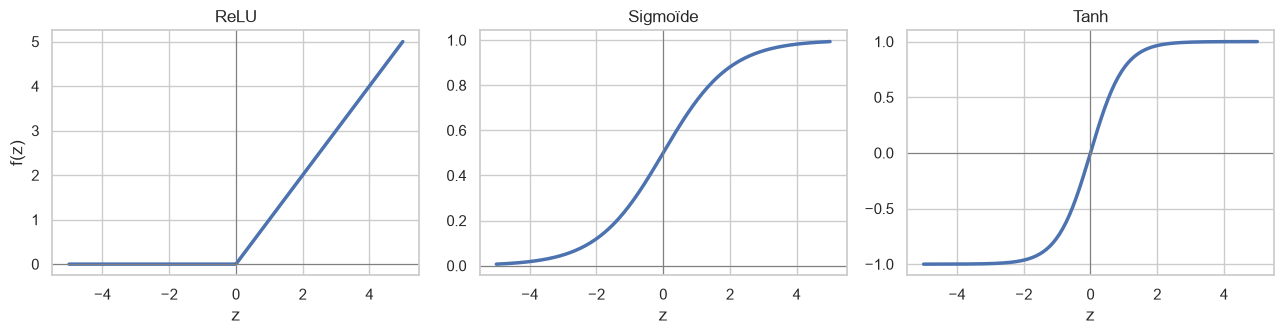

In [99]:
z_values = np.linspace(-5, 5, 200)
activations = {
    "ReLU": np.maximum(0, z_values),
    "Sigmoïde": 1 / (1 + np.exp(-z_values)),
    "Tanh": np.tanh(z_values),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(z_values, values, linewidth=2.5)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("z")
axes[0].set_ylabel("f(z)")
plt.tight_layout()
plt.show()

### 2.5 Construction du MLP avec Keras

| Couche | Rôle |
| --- | --- |
| `Input((48, 48, 1))` | Forme des images préparées en partie 1 |
| `Flatten` | Image → vecteur de 2 304 valeurs (aucun paramètre) |
| `Dense(256, relu)` | Couche cachée : 256 neurones qui combinent les pixels |
| `Dense(7, softmax)` | Sortie : un neurone par émotion, probabilités qui somment à 1 |

256 neurones cachés : assez pour apprendre des combinaisons de pixels, sans faire exploser le nombre de paramètres. Le but reste une référence simple.

In [100]:
def build_mlp(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES, hidden_units=256):
    return keras.Sequential(
        [
            keras.Input(shape=input_shape),
            keras.layers.Flatten(name="flatten"),
            keras.layers.Dense(hidden_units, activation="relu", name="dense_cachee"),
            keras.layers.Dense(num_classes, activation="softmax", name="sortie"),
        ],
        name="mlp_baseline",
    )


mlp = build_mlp()
mlp.summary()

Model: "mlp_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_cachee (Dense)            │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie (Dense)                  │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,879 (2.26 MB)

 Trainable params: 591,879 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Nombre de paramètres d'une couche `Dense` = (entrées × neurones) poids + (neurones) biais :

In [101]:
n_inputs = int(np.prod(INPUT_SHAPE))
hidden = mlp.get_layer("dense_cachee").units

param_table = pd.DataFrame(
    [
        ("flatten", f"{INPUT_SHAPE} → ({n_inputs},)", "0", 0),
        ("dense_cachee", f"({n_inputs},) → ({hidden},)", f"{n_inputs} × {hidden} + {hidden}", n_inputs * hidden + hidden),
        ("sortie", f"({hidden},) → ({NUM_CLASSES},)", f"{hidden} × {NUM_CLASSES} + {NUM_CLASSES}", hidden * NUM_CLASSES + NUM_CLASSES),
    ],
    columns=["couche", "dimensions", "calcul", "paramètres"],
)
param_table.loc[len(param_table)] = ["total", "", "", param_table["paramètres"].sum()]

assert param_table["paramètres"].iloc[-1] == mlp.count_params()
param_table

,couche,dimensions,calcul,paramètres
0,flatten,"(48, 48, 1) → (2304,)",0,0
1,dense_cachee,"(2304,) → (256,)",2304 × 256 + 256,590080
2,sortie,"(256,) → (7,)",256 × 7 + 7,1799
3,total,,,591879


Presque tous les paramètres (99,7 %) sont dans la première couche : chaque neurone caché a un poids par pixel. C'est une autre faiblesse du MLP sur les images, que le CNN corrige en partageant ses poids.

### 2.6 Propagation avant

La **propagation avant** (*forward pass*) est le calcul de la sortie à partir de l'entrée, couche par couche :

\[
\mathbf{x} \in \mathbb{R}^{2304}
\;\longrightarrow\;
\mathbf{h} = \text{ReLU}(\mathbf{x} W_1 + \mathbf{b}_1) \in \mathbb{R}^{256}
\;\longrightarrow\;
\mathbf{z} = \mathbf{h} W_2 + \mathbf{b}_2 \in \mathbb{R}^{7}
\;\longrightarrow\;
\mathbf{p} = \text{Softmax}(\mathbf{z})
\]

Pour le montrer, on refait ce calcul à la main avec NumPy, avec les poids actuels du modèle (encore aléatoires), et on compare avec la prédiction de Keras.

In [102]:
W1, b1 = mlp.get_layer("dense_cachee").get_weights()
W2, b2 = mlp.get_layer("sortie").get_weights()
print("W1", W1.shape, "b1", b1.shape, "| W2", W2.shape, "b2", b2.shape)


def softmax(z):
    exp = np.exp(z - z.max())
    return exp / exp.sum()


x = X_val[0].reshape(-1)
h = np.maximum(0, x @ W1 + b1)
logits = h @ W2 + b2
p_manual = softmax(logits)

p_keras = mlp.predict(X_val[:1], verbose=0)[0]

print("à la main :", p_manual.round(4))
print("Keras     :", p_keras.round(4))
print("identiques :", np.allclose(p_manual, p_keras, atol=1e-5))

W1 (2304, 256) b1 (256,) | W2 (256, 7) b2 (7,)
à la main : [0.2084 0.0324 0.1352 0.2793 0.0196 0.2505 0.0746]
Keras     : [0.2084 0.0324 0.1352 0.2793 0.0196 0.2505 0.0746]
identiques : True


Keras ne fait rien de plus que ces trois lignes de calcul, appliquées à des milliers d'images en même temps.

### 2.7 Sortie multiclasse : Softmax

Les 7 neurones de sortie produisent des scores bruts \(z_1, \dots, z_7\) (les *logits*), qui peuvent être négatifs. La Softmax les transforme en probabilités :

\[
p_i = \frac{e^{z_i}}{\sum_{j=1}^{7} e^{z_j}}
\]

L'exponentielle rend tout positif, la division par la somme garantit que les 7 probabilités font 1. La **classe prédite** est celle de plus grande probabilité (`argmax`).

Rappel : en classification binaire on aurait 1 neurone + sigmoïde. Ici, 7 classes → 7 neurones + Softmax.

Détail sur l'image précédente :

In [103]:
softmax_table = pd.DataFrame(
    {"logit z": logits, "exp(z)": np.exp(logits), "probabilité": p_manual},
    index=CLASS_NAMES,
).round(4)

print("somme des probabilités :", round(float(p_manual.sum()), 6))
print("classe prédite :", CLASS_NAMES[p_manual.argmax()], "| vraie classe :", CLASS_NAMES[y_val[0]])
softmax_table

somme des probabilités : 1.0
classe prédite : happy | vraie classe : happy


,logit z,exp(z),probabilité
angry,0.4919,1.6354,0.2084
disgust,-1.3700,0.2541,0.0324
fear,0.0588,1.0606,0.1352
happy,0.7847,2.1917,0.2793
sad,-1.8723,0.1538,0.0196
surprise,0.6756,1.9651,0.2505
neutral,-0.5357,0.5852,0.0746


Le modèle n'est pas encore entraîné : ses poids sont aléatoires, donc ces probabilités n'ont pas encore de sens. Si la prédiction tombe juste, c'est par hasard.

### 2.8 Fonction de perte : entropie croisée

La perte mesure à quel point la prédiction est mauvaise. Pour une image dont la vraie classe est \(c\) :

\[
L = -\log(p_c)
\]

- si le réseau donne \(p_c = 0{,}9\) à la bonne classe : \(L \approx 0{,}11\) (petite perte) ;
- s'il donne \(p_c = 0{,}05\) : \(L \approx 3{,}0\) (forte perte).

Sur un batch, on prend la moyenne. Avec des labels entiers, Keras l'appelle `sparse_categorical_crossentropy` (voir 1.14).

Repère utile : un modèle qui répond au hasard (1/7 pour chaque classe) a une perte de \(\ln 7 \approx 1{,}95\). Perte du modèle non entraîné sur la validation :

In [104]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()

initial_loss = float(loss_fn(y_val, mlp.predict(X_val, verbose=0)))
print(f"perte initiale (validation) : {initial_loss:.3f}")
print(f"perte d'un tirage au hasard : ln(7) = {np.log(NUM_CLASSES):.3f}")

perte initiale (validation) : 2.157
perte d'un tirage au hasard : ln(7) = 1.946


### 2.9 Rétropropagation et descente de gradient

Entraîner, c'est chercher les poids qui rendent la perte la plus petite possible.

**Descente de gradient.** Le gradient \(\partial L / \partial w\) indique dans quel sens la perte augmente quand on modifie un poids \(w\). On déplace donc chaque poids dans le sens opposé :

\[
w \leftarrow w - \eta \, \frac{\partial L}{\partial w}
\]

\(\eta\) est le **learning rate** : trop petit, l'apprentissage est lent ; trop grand, la perte oscille ou diverge. En pratique, on calcule le gradient sur un **mini-batch** d'images (pas sur tout le jeu), ce qui donne la descente de gradient stochastique.

**Rétropropagation.** Pour obtenir le gradient de chacun des 591 879 paramètres, on part de la perte et on remonte le réseau couche par couche, en appliquant la règle de dérivation en chaîne. Par exemple, pour un poids de la première couche :

\[
\frac{\partial L}{\partial W_1} =
\frac{\partial L}{\partial \mathbf{p}} \cdot
\frac{\partial \mathbf{p}}{\partial \mathbf{z}} \cdot
\frac{\partial \mathbf{z}}{\partial \mathbf{h}} \cdot
\frac{\partial \mathbf{h}}{\partial W_1}
\]

L'erreur mesurée en sortie est ainsi « rétropropagée » vers l'entrée. TensorFlow fait ce calcul automatiquement (`GradientTape`).

Démonstration d'**une seule étape** de descente de gradient sur un batch de 128 images, faite à la main sur une copie du modèle :

In [105]:
demo = keras.models.clone_model(mlp)
demo.set_weights(mlp.get_weights())

x_batch, y_batch = X_train[:128], y_train[:128]

with tf.GradientTape() as tape:
    loss_before = loss_fn(y_batch, demo(x_batch, training=True))

gradients = tape.gradient(loss_before, demo.trainable_variables)

pd.DataFrame(
    [(var.path, tuple(var.shape), tuple(grad.shape)) for var, grad in zip(demo.trainable_variables, gradients)],
    columns=["paramètre", "forme du paramètre", "forme du gradient"],
)

,paramètre,forme du paramètre,forme du gradient
0,mlp_baseline/dense_cachee/kernel,"(2304, 256)","(2304, 256)"
1,mlp_baseline/dense_cachee/bias,"(256,)","(256,)"
2,mlp_baseline/sortie/kernel,"(256, 7)","(256, 7)"
3,mlp_baseline/sortie/bias,"(7,)","(7,)"


Chaque paramètre a un gradient de la même forme que lui. On applique la règle \(w \leftarrow w - \eta \, \partial L / \partial w\), en partant à chaque fois des mêmes poids, pour plusieurs valeurs du learning rate \(\eta\), puis on recalcule la perte sur le même batch :

In [106]:
initial_weights = demo.get_weights()
step_results = []

for learning_rate in [0.001, 0.01, 0.1, 1.0]:
    demo.set_weights(initial_weights)
    for variable, gradient in zip(demo.trainable_variables, gradients):
        variable.assign_sub(learning_rate * gradient)
    loss_after = float(loss_fn(y_batch, demo(x_batch, training=False)))
    step_results.append((learning_rate, float(loss_before), loss_after, loss_after - float(loss_before)))

pd.DataFrame(step_results, columns=["learning rate", "perte avant", "perte après", "variation"]).round(4)

,learning rate,perte avant,perte après,variation
0,0.001,2.2139,2.1735,-0.0405
1,0.010,2.2139,1.9357,-0.2782
2,0.100,2.2139,3.6669,1.4530
3,1.000,2.2139,58.4663,56.2524


Lecture :

- avec un petit pas, la perte baisse un peu : on descend dans la bonne direction ;
- avec un pas trop grand, on « saute » au-delà du creux et la perte remonte : c'est pour cela que le learning rate se règle.

L'entraînement complet répète cette opération sur tous les batchs, époque après époque. Adam, utilisé ensuite, adapte en plus automatiquement le pas de chaque poids.

### 2.10 Compilation

| Choix | Valeur | Pourquoi |
| --- | --- | --- |
| Perte | `sparse_categorical_crossentropy` | Classification multiclasse, labels entiers |
| Optimiseur | Adam, learning rate 0,001 | Descente de gradient qui adapte le pas de chaque poids ; 0,001 est la valeur standard |
| Métrique | accuracy | Part d'images bien classées, lisible ; complétée en partie 5 par des métriques par classe |

Le choix détaillé des hyperparamètres est justifié en partie 4 pour le CNN. Le MLP utilise la même perte, le même optimiseur, le même learning rate et le même batch size, pour que la comparaison soit équitable.

In [107]:
mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### 2.11 Entraînement

- **batch size 128** : 128 images par mise à jour des poids, soit 180 mises à jour par époque ;
- **30 époques** : une époque = un passage complet sur le train. Durée fixe, sans arrêt anticipé, pour voir le comportement brut de la référence ;
- **validation** : mesurée à la fin de chaque époque, jamais utilisée pour mettre à jour les poids. Le test n'est pas touché.

In [108]:
MLP_EPOCHS = 30
MLP_BATCH_SIZE = 128

mlp_history = mlp.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=MLP_EPOCHS,
    batch_size=MLP_BATCH_SIZE,
    verbose=2,
)

Epoch 1/30
180/180 - 2s - 11ms/step - accuracy: 0.2639 - loss: 1.8416 - val_accuracy: 0.3008 - val_loss: 1.7372
Epoch 2/30
180/180 - 1s - 5ms/step - accuracy: 0.3206 - loss: 1.7255 - val_accuracy: 0.3180 - val_loss: 1.7116
Epoch 3/30
180/180 - 1s - 7ms/step - accuracy: 0.3387 - loss: 1.6902 - val_accuracy: 0.3349 - val_loss: 1.6926
Epoch 4/30
180/180 - 1s - 5ms/step - accuracy: 0.3479 - loss: 1.6695 - val_accuracy: 0.3332 - val_loss: 1.6874
Epoch 5/30
180/180 - 1s - 7ms/step - accuracy: 0.3558 - loss: 1.6489 - val_accuracy: 0.3457 - val_loss: 1.6728
Epoch 6/30
180/180 - 1s - 6ms/step - accuracy: 0.3621 - loss: 1.6347 - val_accuracy: 0.3532 - val_loss: 1.6610
Epoch 7/30
180/180 - 1s - 6ms/step - accuracy: 0.3654 - loss: 1.6233 - val_accuracy: 0.3565 - val_loss: 1.6521
Epoch 8/30
180/180 - 1s - 6ms/step - accuracy: 0.3719 - loss: 1.6097 - val_accuracy: 0.3621 - val_loss: 1.6372
Epoch 9/30
180/180 - 1s - 7ms/step - accuracy: 0.3803 - loss: 1.5977 - val_accuracy: 0.3629 - val_loss: 1.6390


### 2.12 Courbes d'apprentissage

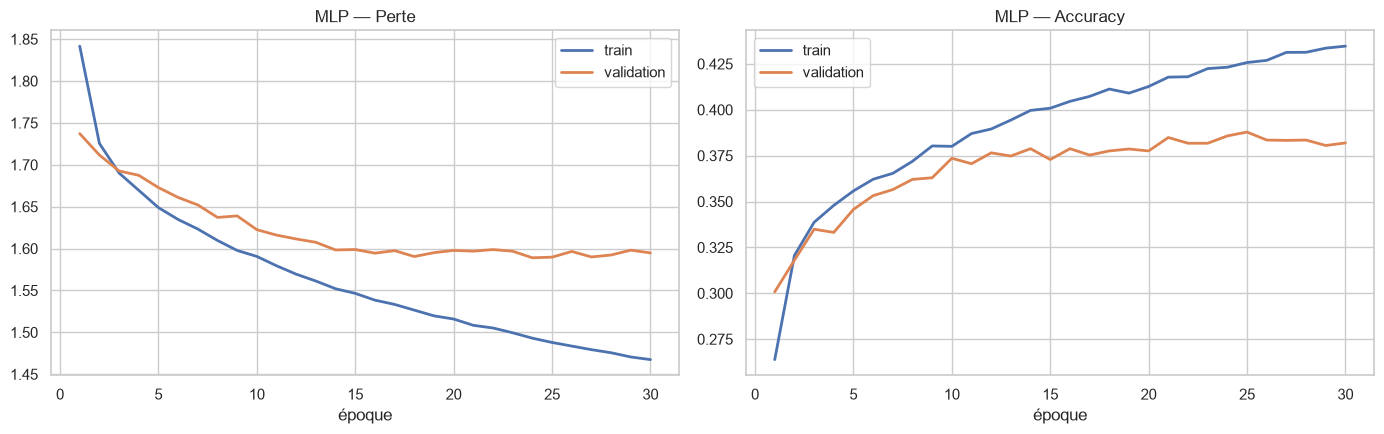

In [109]:
mlp_history_df = pd.DataFrame(mlp_history.history)
mlp_history_df.index = np.arange(1, len(mlp_history_df) + 1)
mlp_history_df.index.name = "epoque"

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, title in [(axes[0], "loss", "Perte"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(mlp_history_df.index, mlp_history_df[metric], label="train", linewidth=2)
    ax.plot(mlp_history_df.index, mlp_history_df[f"val_{metric}"], label="validation", linewidth=2)
    ax.set_title(f"MLP — {title}")
    ax.set_xlabel("époque")
    ax.legend()
plt.tight_layout()
plt.show()

### 2.13 Résultats

On réévalue le modèle final (poids de la dernière époque) sur train et validation. La meilleure époque en validation est indiquée pour information.

In [110]:
train_loss, train_acc = mlp.evaluate(X_train, y_train, verbose=0)
val_loss, val_acc = mlp.evaluate(X_val, y_val, verbose=0)
best_epoch = int(mlp_history_df["val_accuracy"].idxmax())

mlp_results = pd.DataFrame(
    {
        "loss": [train_loss, val_loss],
        "accuracy": [train_acc, val_acc],
    },
    index=["train", "validation"],
).round(4)

print(f"Meilleure accuracy de validation : {mlp_history_df['val_accuracy'].max():.4f} (époque {best_epoch})")
print(f"Hasard pur : {1 / NUM_CLASSES:.4f} | toujours prédire 'happy' : {np.mean(y_val == CLASS_TO_INDEX['happy']):.4f}")
mlp_results

Meilleure accuracy de validation : 0.3878 (époque 25)
Hasard pur : 0.1429 | toujours prédire 'happy' : 0.2513


,loss,accuracy
train,1.4761,0.4376
validation,1.5948,0.3819


**Lecture des résultats (MLP de référence)**

| | Accuracy |
| --- | --- |
| Hasard (1 chance sur 7) | 14,3 % |
| Toujours répondre `happy` | 25,1 % |
| **MLP — validation** | **environ 38 %** (meilleure époque : environ 39 %) |
| MLP — train | environ 44 % |
| Humain sur FER-2013 (Goodfellow et al.) | environ 65 % |

- Le MLP apprend quelque chose : il fait bien mieux que le hasard et que la stratégie « toujours happy ».
- Il reste faible : il se trompe sur environ 6 images sur 10.
- **Début de surapprentissage** : la perte de train continue de baisser jusqu'à la fin, alors que la perte de validation stagne vers 1,59 à partir d'une quinzaine d'époques. L'écart train / validation se creuse : le réseau commence à mémoriser des détails du train au lieu de règles générales.
- La cause principale est l'architecture : en aplatissant l'image, le MLP perd la position relative des pixels (yeux, bouche, sourcils). Il doit apprendre chaque motif séparément à chaque position, avec 590 000 poids dans une seule couche.

C'est la référence à battre. Le CNN de la partie 3 garde la structure 2D de l'image et partage ses poids entre les positions : il devrait faire nettement mieux avec moins de paramètres.

### 2.14 Sauvegarde

Le modèle (architecture + poids + optimiseur) est enregistré au format Keras. L'historique est exporté pour le tableau comparatif de la partie 6. Les fichiers `.keras` restent hors de git.

In [111]:
mlp_path = MODELS_DIR / "mlp_baseline.keras"
mlp.save(mlp_path)
mlp_history_df.to_csv(REPORTS_DIR / "mlp_baseline_history.csv")

reloaded = keras.models.load_model(mlp_path)
assert np.allclose(reloaded.predict(X_val[:32], verbose=0), mlp.predict(X_val[:32], verbose=0), atol=1e-6)
print("Modèle enregistré :", mlp_path.resolve())

Modèle enregistré : /Users/ftayma24/SKOOL/ING3/DL/ProjetDL/models/mlp_baseline.keras


## Partie 3 — CNN

Le MLP perd la structure 2D de l'image. Un réseau convolutif (CNN) la garde : il cherche des motifs locaux (bords, coins, formes d'yeux ou de bouche) avec de petits filtres qu'il fait glisser sur toute l'image. Un même filtre sert à toutes les positions, ce qui donne beaucoup moins de paramètres.

Deux parties : **extraction de caractéristiques** (convolution, ReLU, pooling) puis **classification** (Flatten, Dense, Softmax).

### 3.1 Les notions

| Notion | Rôle |
| --- | --- |
| **Filtre** (kernel) | Petite matrice de poids, par exemple 3×3, qui réagit à un motif local. Ses valeurs sont apprises. |
| **Convolution** | On fait glisser le filtre sur l'image. À chaque position : somme des pixels × poids du filtre, plus un biais. |
| **Feature map** | Résultat d'un filtre sur toute l'image : une carte qui indique où le motif est présent. N filtres donnent N feature maps (les canaux). |
| **Taille du kernel** | Zone vue à chaque calcul. 3×3 : peu de paramètres ; en empilant les couches, chaque neurone voit une zone de plus en plus large. |
| **Stride** | Pas de déplacement du filtre. 1 : toutes les positions. 2 : une sur deux, la sortie est deux fois plus petite. |
| **Padding** | Bordure ajoutée autour de l'image. `same` garde la taille ; `valid` (pas de bordure) la réduit de k − 1. |
| **ReLU** | \(\max(0, z)\) après chaque convolution : non-linéarité, ne garde que les réponses positives. |
| **Pooling** | MaxPooling 2×2 : garde le maximum de chaque carré 2×2. Divise hauteur et largeur par 2, réduit le calcul, tolère de petits décalages. |
| **Flatten** | Transforme les feature maps finales en vecteur pour les couches Dense. |
| **Dense** | Combine les motifs détectés pour décider de l'émotion. |
| **Sortie** | `Dense(7, softmax)` : une probabilité par émotion, comme pour le MLP. |

Deux formules pour remplir le tableau de dimensions :

\[
\text{taille de sortie} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1
\qquad
\text{paramètres d'une Conv2D} = (k \times k \times C_{\text{entrée}} + 1) \times \text{filtres}
\]

avec \(n\) la taille d'entrée, \(k\) le kernel, \(p\) le padding, \(s\) le stride. Le nombre de paramètres d'une convolution ne dépend pas de la taille de l'image : c'est le partage des poids.

### 3.2 Une convolution à la main

Pour voir ce que fait un filtre, on applique deux filtres classiques (Sobel), fixés à la main, à un visage. Dans le CNN, les filtres ne sont pas fixés : ils sont appris.

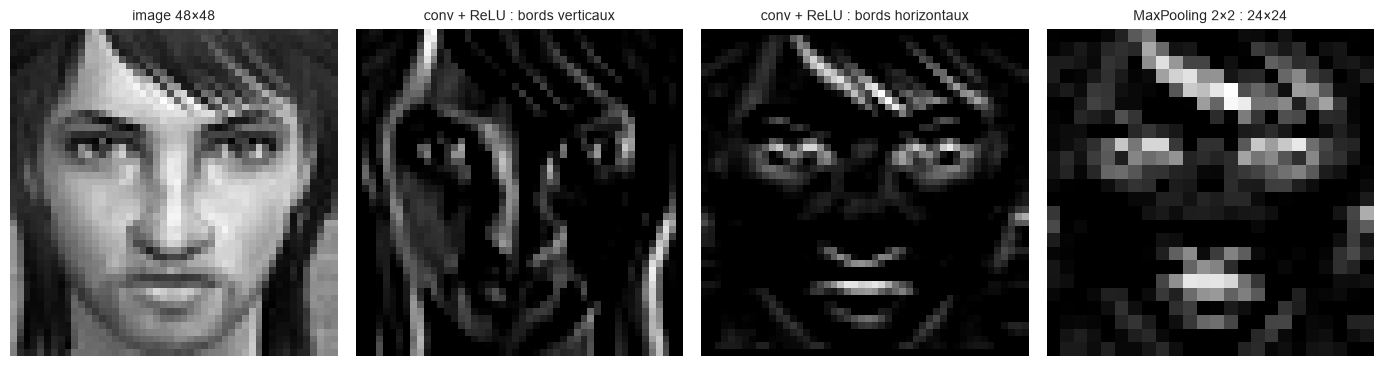

In [112]:
face = X_train[0].squeeze()

kernels = {
    "bords verticaux": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype="float32"),
    "bords horizontaux": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype="float32"),
}

feature_maps = {name: np.maximum(0, cv2.filter2D(face, -1, kernel)) for name, kernel in kernels.items()}
pooled = feature_maps["bords horizontaux"].reshape(24, 2, 24, 2).max(axis=(1, 3))

panels = [
    ("image 48×48", face),
    ("conv + ReLU : bords verticaux", feature_maps["bords verticaux"]),
    ("conv + ReLU : bords horizontaux", feature_maps["bords horizontaux"]),
    (f"MaxPooling 2×2 : {pooled.shape[0]}×{pooled.shape[1]}", pooled),
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (title, panel) in zip(axes, panels):
    ax.imshow(panel, cmap="gray")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

Chaque feature map met en évidence un type de motif (contours des yeux, de la bouche, des sourcils). Le pooling divise la taille par 2 tout en gardant ces motifs.

### 3.3 Architecture choisie

```text
Entrée 48×48×1
→ [Conv2D 32 filtres 3×3, same, ReLU → MaxPooling 2×2]   48 → 24
→ [Conv2D 64 filtres 3×3, same, ReLU → MaxPooling 2×2]   24 → 12
→ [Conv2D 128 filtres 3×3, same, ReLU → MaxPooling 2×2]  12 → 6
→ Flatten → Dense 64 + ReLU → Dense 7 + Softmax
```

Justification :

- **3 blocs** : la taille passe de 48 à 6. Un quatrième pooling donnerait 3×3, trop peu pour garder la position des yeux et de la bouche.
- **Kernels 3×3, stride 1, padding `same`** : le choix standard. Peu de poids, aucun pixel de bord perdu ; c'est le pooling seul qui réduit la taille, ce qui rend les dimensions faciles à suivre.
- **Filtres 32 → 64 → 128** : on double les filtres quand on divise la résolution par 2. Les premiers blocs détectent des motifs simples (bords), les suivants des combinaisons plus nombreuses (œil, coin de bouche).
- **Dense 64** : assez pour combiner les motifs, sans trop de paramètres après le Flatten.
- **Pas de Dropout ni d'augmentation** : c'est la version de base. Ces techniques sont ajoutées en partie 6, une par une, pour mesurer leur effet.

In [113]:
def build_cnn(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES, filters=(32, 64, 128), kernel_size=3, dense_units=64):
    layers = [keras.Input(shape=input_shape)]
    for block, n_filters in enumerate(filters, start=1):
        layers += [
            keras.layers.Conv2D(n_filters, kernel_size, strides=1, padding="same", activation="relu", name=f"conv{block}"),
            keras.layers.MaxPooling2D(pool_size=2, name=f"pool{block}"),
        ]
    layers += [
        keras.layers.Flatten(name="flatten"),
        keras.layers.Dense(dense_units, activation="relu", name="dense"),
        keras.layers.Dense(num_classes, activation="softmax", name="sortie"),
    ]
    return keras.Sequential(layers, name="cnn_v1")


cnn = build_cnn()
cnn.summary()

Model: "cnn_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       294,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie (Dense)                  │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,103 (1.48 MB)

 Trainable params: 388,103 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

### 3.4 Dimensions et paramètres couche par couche

In [114]:
rows = []
previous_shape = INPUT_SHAPE
for layer in cnn.layers:
    shape = tuple(layer.output.shape[1:])
    if isinstance(layer, keras.layers.Conv2D):
        k = layer.kernel_size[0]
        calcul = f"({k}×{k}×{previous_shape[-1]} + 1) × {layer.filters}"
    elif isinstance(layer, keras.layers.Dense):
        calcul = f"({previous_shape[-1]} + 1) × {layer.units}"
    else:
        calcul = "aucun poids"
    rows.append((layer.name, type(layer).__name__, str(previous_shape), str(shape), calcul, layer.count_params()))
    previous_shape = shape

cnn_table = pd.DataFrame(rows, columns=["couche", "type", "entrée", "sortie", "calcul", "paramètres"])
cnn_table["% du total"] = (100 * cnn_table["paramètres"] / cnn.count_params()).round(1)
cnn_table.loc[len(cnn_table)] = ["total", "", "", "", "", cnn.count_params(), 100.0]
cnn_table

,couche,type,entrée,sortie,calcul,paramètres,% du total
0,conv1,Conv2D,"(48, 48, 1)","(48, 48, 32)",(3×3×1 + 1) × 32,320,0.1
1,pool1,MaxPooling2D,"(48, 48, 32)","(24, 24, 32)",aucun poids,0,0.0
2,conv2,Conv2D,"(24, 24, 32)","(24, 24, 64)",(3×3×32 + 1) × 64,18496,4.8
3,pool2,MaxPooling2D,"(24, 24, 64)","(12, 12, 64)",aucun poids,0,0.0
4,conv3,Conv2D,"(12, 12, 64)","(12, 12, 128)",(3×3×64 + 1) × 128,73856,19.0
5,pool3,MaxPooling2D,"(12, 12, 128)","(6, 6, 128)",aucun poids,0,0.0
6,flatten,Flatten,"(6, 6, 128)","(4608,)",aucun poids,0,0.0
7,dense,Dense,"(4608,)","(64,)",(4608 + 1) × 64,294976,76.0
8,sortie,Dense,"(64,)","(7,)",(64 + 1) × 7,455,0.1
9,total,,,,,388103,100.0


In [115]:
print(f"CNN : {cnn.count_params():,} paramètres | MLP : {mlp.count_params():,} paramètres")

CNN : 388,103 paramètres | MLP : 591,879 paramètres


Lecture :

- les convolutions gardent la taille (padding `same`), chaque pooling la divise par 2 : 48 → 24 → 12 → 6 ;
- le nombre de canaux augmente avec les filtres : 1 → 32 → 64 → 128 ;
- les trois convolutions ne pèsent qu'environ 24 % des paramètres : un filtre 3×3 est partagé par toutes les positions ;
- l'essentiel des poids (environ 76 %) est dans la couche Dense qui suit le Flatten (6 × 6 × 128 = 4 608 entrées) ;
- au total, le CNN a **moins de paramètres que le MLP**, tout en gardant la structure de l'image.

### 3.5 Sauvegarde

On enregistre l'architecture avec ses poids initiaux. La partie 4 l'entraîne et remplace ce fichier par le modèle entraîné.

In [116]:
cnn_path = MODELS_DIR / "cnn_v1.keras"
cnn.save(cnn_path)
print("Modèle enregistré :", cnn_path.resolve())

Modèle enregistré : /Users/ftayma24/SKOOL/ING3/DL/ProjetDL/models/cnn_v1.keras


## Partie 4 — Entraînement du CNN

| Choix | Valeur | Justification |
| --- | --- | --- |
| Perte | `sparse_categorical_crossentropy` | Classification à 7 classes, sortie Softmax, labels entiers (voir 1.14 et 2.8) |
| Optimiseur | Adam | Descente de gradient qui adapte le pas de chaque poids : converge vite sans réglage fin, standard pour les CNN |
| Learning rate | 0,001 | Valeur par défaut d'Adam. En 2.9, un pas de 0,1 faisait déjà remonter la perte |
| Batch size | 128 | 180 mises à jour par époque : gradient assez stable, calcul rapide sur CPU. Même valeur que le MLP pour comparer |
| Époques | 20 | Assez pour que la validation atteigne son meilleur niveau puis montre le surapprentissage. Pas d'arrêt anticipé : il sera testé en partie 6 |
| Métrique | accuracy | Lisible pendant l'entraînement. Complétée en partie 5 par des métriques par classe, à cause du déséquilibre |

La validation est mesurée à chaque époque mais ne modifie jamais les poids. Le test n'est pas utilisé.

In [117]:
CNN_EPOCHS = 20
CNN_BATCH_SIZE = 128

keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [118]:
cnn_history = cnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=2,
)

Epoch 1/20
180/180 - 29s - 162ms/step - accuracy: 0.2980 - loss: 1.7351 - val_accuracy: 0.3558 - val_loss: 1.6105
Epoch 2/20
180/180 - 29s - 158ms/step - accuracy: 0.4333 - loss: 1.4924 - val_accuracy: 0.4549 - val_loss: 1.4223
Epoch 3/20
180/180 - 27s - 150ms/step - accuracy: 0.4844 - loss: 1.3591 - val_accuracy: 0.4943 - val_loss: 1.3265
Epoch 4/20
180/180 - 27s - 151ms/step - accuracy: 0.5245 - loss: 1.2610 - val_accuracy: 0.5211 - val_loss: 1.2666
Epoch 5/20
180/180 - 27s - 151ms/step - accuracy: 0.5573 - loss: 1.1825 - val_accuracy: 0.5350 - val_loss: 1.2372
Epoch 6/20
180/180 - 26s - 146ms/step - accuracy: 0.5857 - loss: 1.1148 - val_accuracy: 0.5416 - val_loss: 1.2247
Epoch 7/20
180/180 - 28s - 154ms/step - accuracy: 0.6096 - loss: 1.0548 - val_accuracy: 0.5462 - val_loss: 1.2261
Epoch 8/20
180/180 - 26s - 145ms/step - accuracy: 0.6350 - loss: 0.9956 - val_accuracy: 0.5495 - val_loss: 1.2555
Epoch 9/20
180/180 - 27s - 148ms/step - accuracy: 0.6589 - loss: 0.9374 - val_accuracy: 

### 4.1 Courbes d'apprentissage

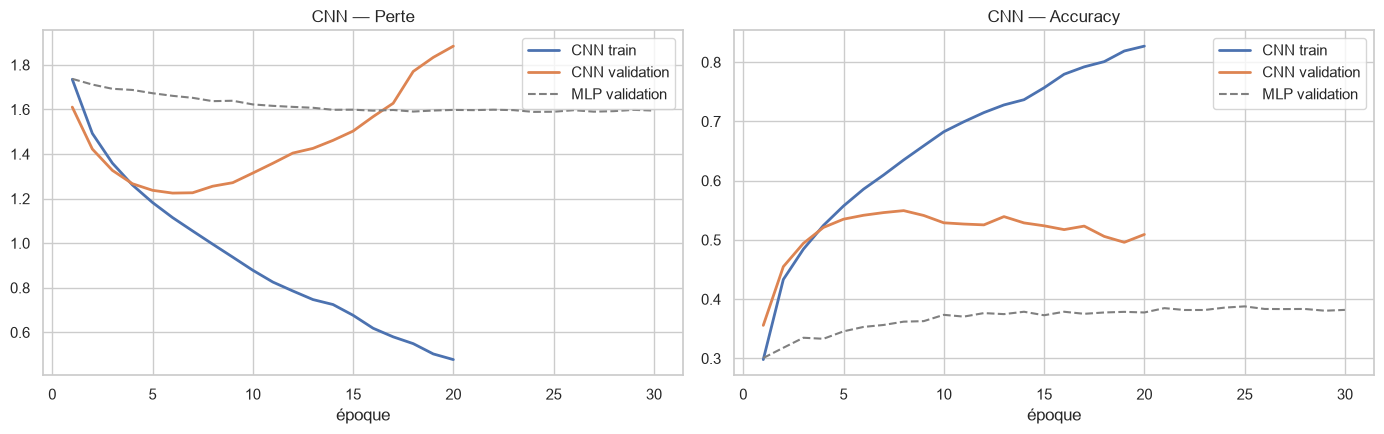

In [119]:
cnn_history_df = pd.DataFrame(cnn_history.history)
cnn_history_df.index = np.arange(1, len(cnn_history_df) + 1)
cnn_history_df.index.name = "epoque"

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric, title in [(axes[0], "loss", "Perte"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(cnn_history_df.index, cnn_history_df[metric], label="CNN train", linewidth=2)
    ax.plot(cnn_history_df.index, cnn_history_df[f"val_{metric}"], label="CNN validation", linewidth=2)
    ax.plot(mlp_history_df.index, mlp_history_df[f"val_{metric}"], label="MLP validation", linestyle="--", color="gray")
    ax.set_title(f"CNN — {title}")
    ax.set_xlabel("époque")
    ax.legend()
plt.tight_layout()
plt.show()

In [120]:
best_loss_epoch = int(cnn_history_df["val_loss"].idxmin())
best_acc_epoch = int(cnn_history_df["val_accuracy"].idxmax())

print(f"Perte de validation minimale : {cnn_history_df['val_loss'].min():.4f} (époque {best_loss_epoch})")
print(f"Accuracy de validation maximale : {cnn_history_df['val_accuracy'].max():.4f} (époque {best_acc_epoch})")
cnn_history_df.loc[[1, best_loss_epoch, CNN_EPOCHS]].round(4)

Perte de validation minimale : 1.2247 (époque 6)
Accuracy de validation maximale : 0.5495 (époque 8)


,accuracy,loss,val_accuracy,val_loss
epoque,,,,
1,0.2980,1.7351,0.3558,1.6105
6,0.5857,1.1148,0.5416,1.2247
20,0.8271,0.4776,0.5092,1.8840


CNN_CURVES

### 4.2 Résultats et comparaison avec le MLP

In [121]:
comparison = pd.DataFrame(
    {
        "paramètres": [mlp.count_params(), cnn.count_params()],
        "accuracy train": [mlp.evaluate(X_train, y_train, verbose=0)[1], cnn.evaluate(X_train, y_train, verbose=0)[1]],
        "accuracy validation": [mlp.evaluate(X_val, y_val, verbose=0)[1], cnn.evaluate(X_val, y_val, verbose=0)[1]],
        "meilleure accuracy validation": [mlp_history_df["val_accuracy"].max(), cnn_history_df["val_accuracy"].max()],
    },
    index=["MLP", "CNN v1"],
).round(4)
comparison

,paramètres,accuracy train,accuracy validation,meilleure accuracy validation
MLP,591879,0.4376,0.3819,0.3878
CNN v1,388103,0.7657,0.5092,0.5495


CNN_RESULTS

In [122]:
cnn.save(MODELS_DIR / "cnn_v1.keras")
cnn_history_df.to_csv(REPORTS_DIR / "cnn_v1_history.csv")
print("Modèle enregistré :", (MODELS_DIR / "cnn_v1.keras").resolve())

Modèle enregistré : /Users/ftayma24/SKOOL/ING3/DL/ProjetDL/models/cnn_v1.keras


## Partie 5 — Évaluation et analyse des erreurs

On évalue le CNN v1 sur le **test** pour comprendre ses erreurs. Ces résultats ne servent à choisir aucun réglage : les expériences de la partie 6 sont comparées sur la validation, et le modèle final sera évalué une seule fois sur le test.

L'accuracy seule ne suffit pas : avec des classes déséquilibrées, un modèle peut avoir une bonne accuracy en ignorant `disgust`. On regarde donc aussi les métriques par classe et la matrice de confusion.

In [123]:
from sklearn.metrics import classification_report, confusion_matrix

test_probs = cnn.predict(X_test, verbose=0)
test_pred = test_probs.argmax(axis=1)
test_conf = test_probs.max(axis=1)

print(f"Accuracy test : {np.mean(test_pred == y_test):.4f}")

Accuracy test : 0.5075


### 5.1 Métriques par classe

- **précision** : quand le modèle prédit cette émotion, à quelle fréquence a-t-il raison ;
- **rappel** : parmi les vraies images de cette émotion, combien sont retrouvées ;
- **F1** : moyenne harmonique des deux ;
- **support** : nombre d'images de test de la classe.

In [124]:
report = pd.DataFrame(
    classification_report(y_test, test_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
).T
report["support"] = report["support"].astype(int)
report.round(3)

,precision,recall,f1-score,support
angry,0.477,0.331,0.391,958
disgust,0.388,0.423,0.405,111
fear,0.313,0.419,0.359,1024
happy,0.758,0.679,0.717,1774
sad,0.382,0.383,0.383,1247
surprise,0.722,0.637,0.676,831
neutral,0.440,0.517,0.475,1233
accuracy,0.508,0.508,0.508,0
macro avg,0.497,0.484,0.487,7178
weighted avg,0.527,0.508,0.513,7178


### 5.2 Matrice de confusion

Chaque ligne est une vraie émotion, normalisée à 100 % : la diagonale est le rappel, le reste montre vers quelles émotions partent les erreurs.

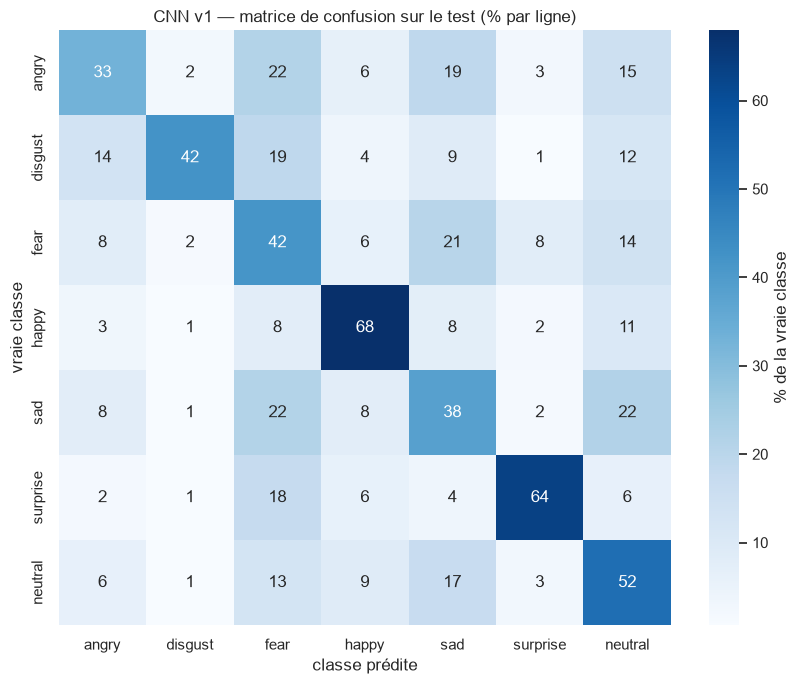

In [125]:
cm = confusion_matrix(y_test, test_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm_pct, annot=True, fmt=".0f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar_kws={"label": "% de la vraie classe"}, ax=ax)
ax.set_xlabel("classe prédite")
ax.set_ylabel("vraie classe")
ax.set_title("CNN v1 — matrice de confusion sur le test (% par ligne)")
plt.tight_layout()
plt.show()

Confusions les plus fréquentes :

In [126]:
confusions = pd.DataFrame(
    [
        (CLASS_NAMES[t], CLASS_NAMES[p], cm[t, p], cm_pct[t, p])
        for t in range(NUM_CLASSES)
        for p in range(NUM_CLASSES)
        if t != p
    ],
    columns=["vraie classe", "prédite", "images", "% de la vraie classe"],
).sort_values("images", ascending=False)

confusions.head(8).round(1)

,vraie classe,prédite,images,% de la vraie classe
29,sad,neutral,273,21.9
26,sad,fear,270,21.7
15,fear,sad,210,20.5
40,neutral,sad,208,16.9
1,angry,fear,206,21.5
23,happy,neutral,187,10.5
3,angry,sad,180,18.8
38,neutral,fear,157,12.7


CNN_CONFUSION

### 5.3 Exemples de prédictions

Format : vraie classe, classe prédite, probabilité donnée par la Softmax. En vert les bonnes prédictions, en rouge les erreurs.

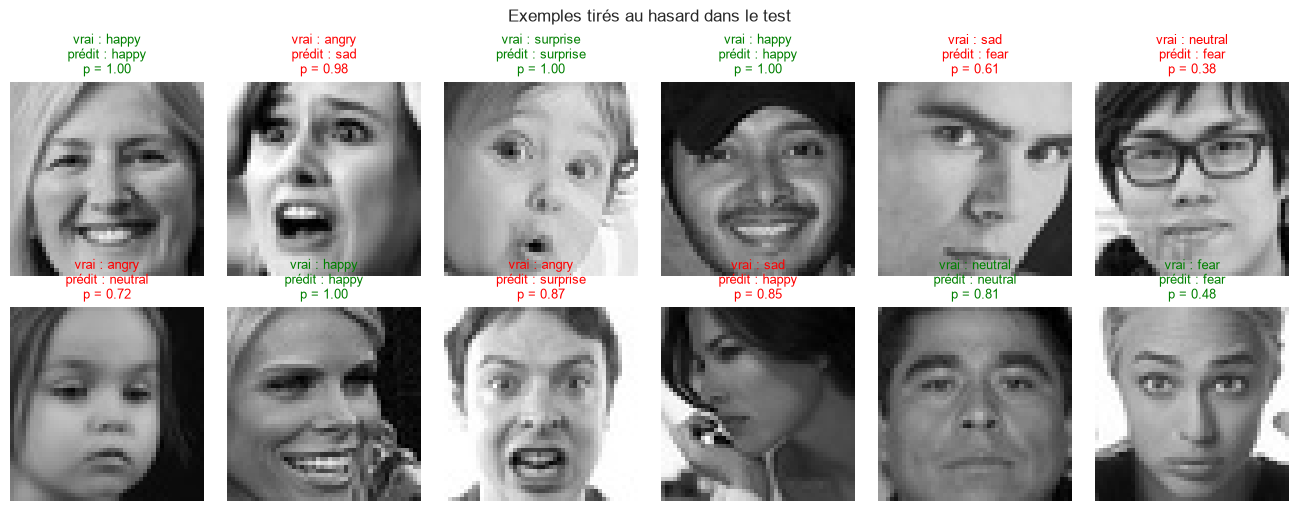

In [127]:
def show_predictions(indices, title, n_cols=6):
    n_rows = int(np.ceil(len(indices) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.2, n_rows * 2.6))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, indices):
        ax.imshow(X_test[i].squeeze(), cmap="gray", vmin=0, vmax=1)
        correct = test_pred[i] == y_test[i]
        ax.set_title(
            f"vrai : {CLASS_NAMES[y_test[i]]}\nprédit : {CLASS_NAMES[test_pred[i]]}\np = {test_conf[i]:.2f}",
            fontsize=9,
            color="green" if correct else "red",
        )
    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
show_predictions(rng.choice(len(X_test), size=12, replace=False), "Exemples tirés au hasard dans le test")

### 5.4 Analyse des erreurs

Les erreurs les plus intéressantes sont celles où le modèle se trompe **avec assurance** (forte probabilité sur la mauvaise classe) :

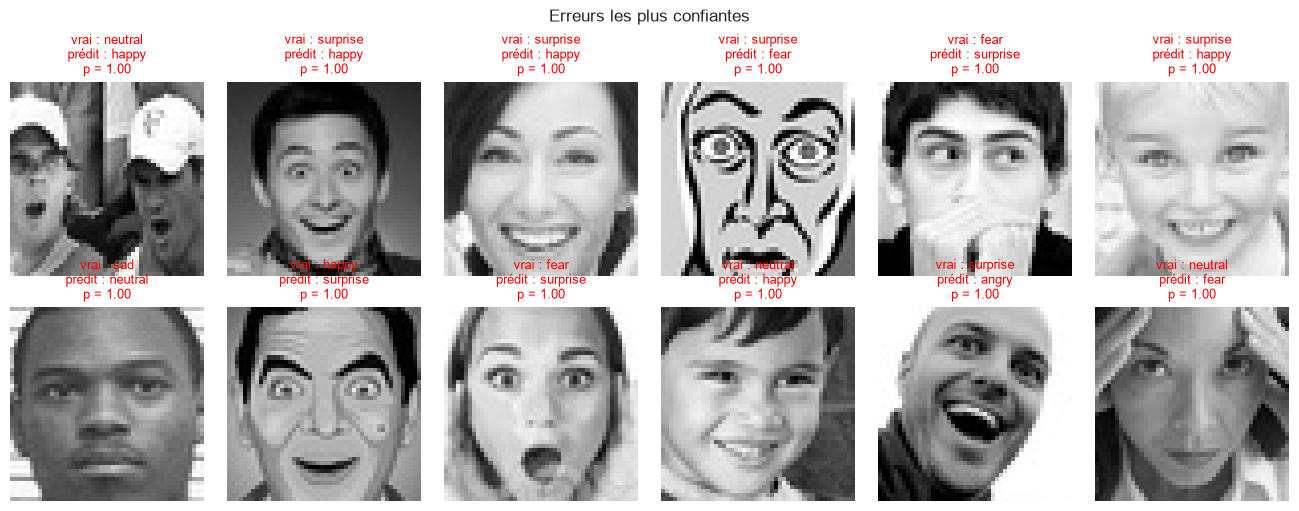

In [128]:
errors = np.flatnonzero(test_pred != y_test)
confident_errors = errors[np.argsort(-test_conf[errors])][:12]
show_predictions(confident_errors, "Erreurs les plus confiantes")

Erreurs sur les deux classes les plus difficiles, `disgust` et `fear` :

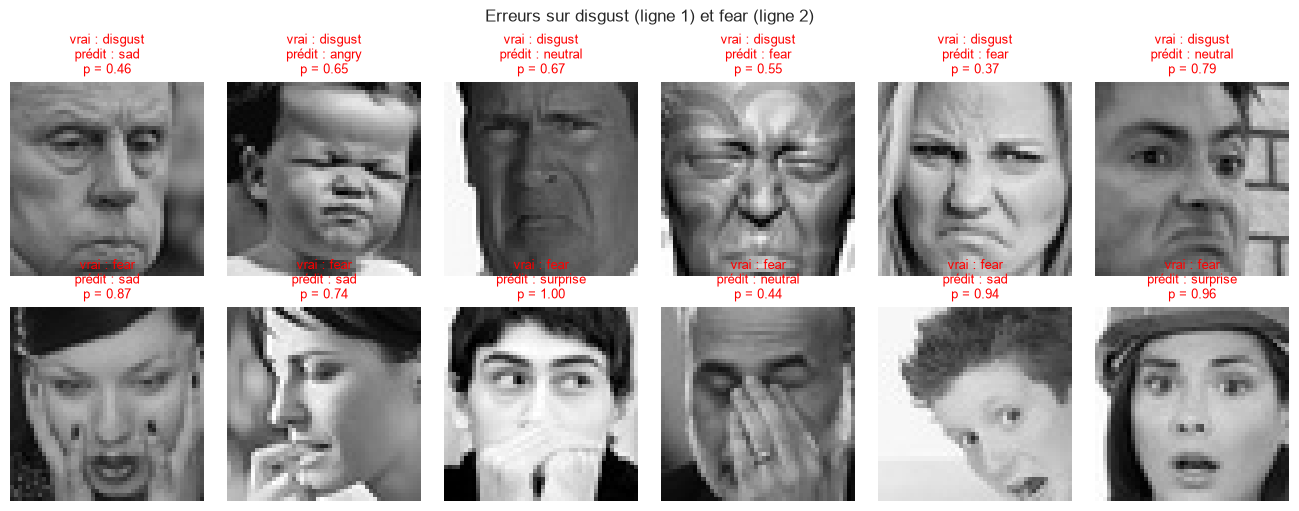

In [129]:
hard = [i for name in ["disgust", "fear"] for i in rng.choice(np.flatnonzero((y_test == CLASS_TO_INDEX[name]) & (test_pred != y_test)), size=6, replace=False)]
show_predictions(hard, "Erreurs sur disgust (ligne 1) et fear (ligne 2)")

## Partie 6 — Expériences

Le CNN v1 surapprend vite : la validation plafonne vers 55 % dès l'époque 8 alors que le train continue de monter. Chaque expérience part du CNN v1 et ne change **qu'une seule chose**, avec les mêmes réglages (Adam 0,001, batch 128, 20 époques, même graine). Comparaison sur la validation uniquement.

| Expérience | Modification | Attendu |
| --- | --- | --- |
| E1 | Dropout 0,25 après chaque bloc, 0,5 avant la sortie | Moins de surapprentissage |
| E2 | Data Augmentation (miroir, rotation, zoom, décalage) | Plus de variété vue à l'entraînement |
| E3 | BatchNormalization après chaque convolution | Apprentissage plus stable et plus rapide |
| E4 | Poids de classe (1.14) | Meilleur rappel sur `disgust` |

### 6.1 Outils

`build_cnn_exp` reprend l'architecture du CNN v1 avec des options. Sans option, c'est exactement le CNN v1. Les couches d'augmentation ne sont actives qu'à l'entraînement.

In [130]:
from sklearn.metrics import f1_score, recall_score


def build_cnn_exp(dropout=False, augment=False, batchnorm=False, name="cnn_exp"):
    layers = [keras.Input(shape=INPUT_SHAPE)]
    if augment:
        layers += [
            keras.layers.RandomFlip("horizontal"),
            keras.layers.RandomRotation(0.05),
            keras.layers.RandomZoom(0.1),
            keras.layers.RandomTranslation(0.1, 0.1),
        ]
    for block, n_filters in enumerate((32, 64, 128), start=1):
        layers.append(keras.layers.Conv2D(n_filters, 3, padding="same", name=f"conv{block}"))
        if batchnorm:
            layers.append(keras.layers.BatchNormalization(name=f"bn{block}"))
        layers += [keras.layers.Activation("relu"), keras.layers.MaxPooling2D(2, name=f"pool{block}")]
        if dropout:
            layers.append(keras.layers.Dropout(0.25))
    layers += [keras.layers.Flatten(), keras.layers.Dense(64, activation="relu", name="dense")]
    if dropout:
        layers.append(keras.layers.Dropout(0.5))
    layers.append(keras.layers.Dense(NUM_CLASSES, activation="softmax", name="sortie"))
    return keras.Sequential(layers, name=name)

`run_experiment` entraîne un modèle et résume ses résultats sur la validation. En plus de l'accuracy, on garde le **F1 macro** (chaque classe compte autant) et le **rappel de `disgust`**, à cause du déséquilibre.

In [131]:
EXP_EPOCHS = 20
experiments = {}


def summarize(name, modification, model, history_df):
    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    last = history_df.iloc[-1]
    experiments[name] = {
        "modification": modification,
        "history": history_df,
        "model": model,
        "meilleure val acc": history_df["val_accuracy"].max(),
        "époque": int(history_df["val_accuracy"].idxmax()),
        "val acc finale": last["val_accuracy"],
        "écart train - val": last["accuracy"] - last["val_accuracy"],
        "F1 macro val": f1_score(y_val, val_pred, average="macro"),
        "rappel disgust val": recall_score(y_val, val_pred, labels=[CLASS_TO_INDEX["disgust"]], average="macro"),
    }


def run_experiment(name, modification, epochs=EXP_EPOCHS, callbacks=None, class_weight=None, **model_options):
    keras.utils.set_random_seed(SEED)
    model = build_cnn_exp(name=name.split()[0], **model_options)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=CNN_BATCH_SIZE,
        callbacks=callbacks,
        class_weight=class_weight,
        verbose=0,
    )
    history_df = pd.DataFrame(history.history)
    history_df.index = np.arange(1, len(history_df) + 1)
    summarize(name, modification, model, history_df)
    result = experiments[name]
    print(f"{name}: meilleure val acc {result['meilleure val acc']:.4f} (époque {result['époque']}), F1 macro {result['F1 macro val']:.4f}")


summarize("CNN v1", "référence (partie 4)", cnn, cnn_history_df)

### 6.2 Entraînements

In [132]:
run_experiment("E1 Dropout", "Dropout 0,25 / 0,5", dropout=True)
run_experiment("E2 Augmentation", "Data Augmentation", augment=True)
run_experiment("E3 BatchNorm", "BatchNormalization", batchnorm=True)
run_experiment("E4 Poids de classe", "class_weight équilibré", class_weight=class_weight)

E1 Dropout: meilleure val acc 0.5630 (époque 20), F1 macro 0.4638
E2 Augmentation: meilleure val acc 0.5542 (époque 19), F1 macro 0.4722
E3 BatchNorm: meilleure val acc 0.4876 (époque 11), F1 macro 0.4021
E4 Poids de classe: meilleure val acc 0.5326 (époque 12), F1 macro 0.4758


### 6.3 Courbes de validation

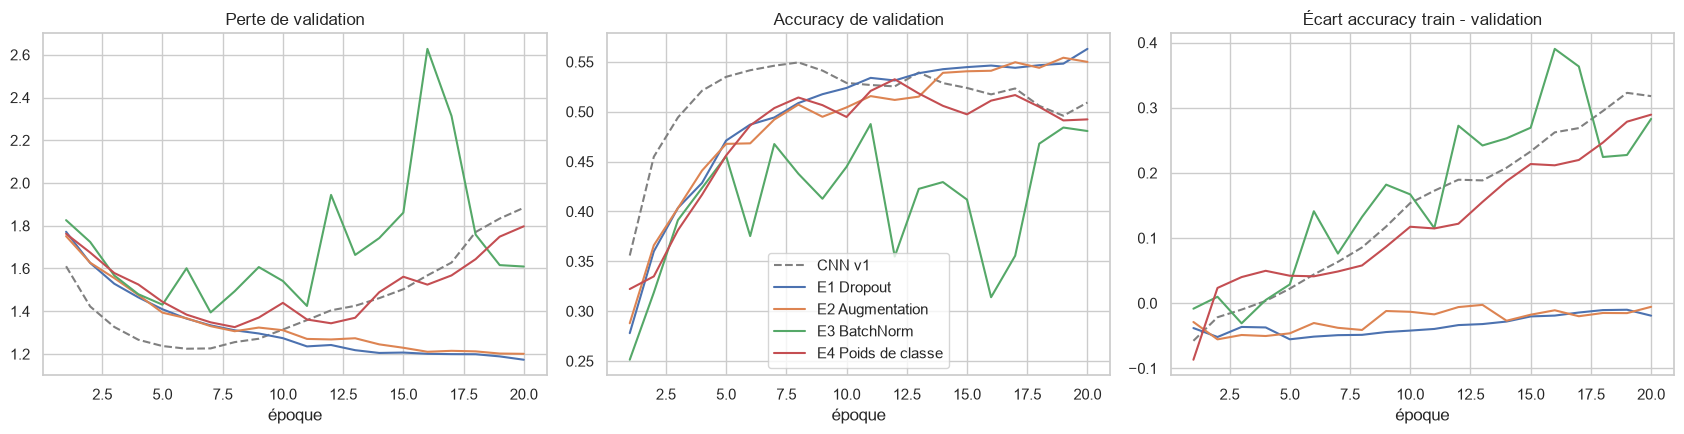

In [133]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, result in experiments.items():
    h = result["history"]
    style = {"linestyle": "--", "color": "gray"} if name == "CNN v1" else {}
    axes[0].plot(h.index, h["val_loss"], label=name, **style)
    axes[1].plot(h.index, h["val_accuracy"], label=name, **style)
    axes[2].plot(h.index, h["accuracy"] - h["val_accuracy"], label=name, **style)
for ax, title in zip(axes, ["Perte de validation", "Accuracy de validation", "Écart accuracy train - validation"]):
    ax.set_title(title)
    ax.set_xlabel("époque")
axes[1].legend()
plt.tight_layout()
plt.show()

### 6.4 Tableau comparatif (validation)

In [134]:
columns = ["modification", "meilleure val acc", "époque", "val acc finale", "écart train - val", "F1 macro val", "rappel disgust val"]
exp_table = pd.DataFrame(experiments).T[columns]
exp_table.to_csv(REPORTS_DIR / "experiences.csv")
exp_table.round(3)

,modification,meilleure val acc,époque,val acc finale,écart train - val,F1 macro val,rappel disgust val
CNN v1,référence (partie 4),0.54946,8,0.50923,0.317826,0.487639,0.402299
E1 Dropout,"Dropout 0,25 / 0,5",0.563044,20,0.563044,-0.019177,0.463794,0.011494
E2 Augmentation,Data Augmentation,0.554162,19,0.549983,-0.005593,0.472153,0.068966
E3 BatchNorm,BatchNormalization,0.487635,11,0.480669,0.282862,0.402077,0.0
E4 Poids de classe,class_weight équilibré,0.532567,12,0.492337,0.289393,0.475805,0.367816
